# Part 2: Pairwise comparisons
**Lab:** In God we trust, everyone else bring the data · **Analyst:** Ayhan Demir · **Notebook 2 of 5**

**Question for the CMO:** which channels are *really* different, and which gaps are just day-to-day luck?
**Reads:** `outputs/marketing_data.csv` (from notebook 01) · **Writes:** `results_cpa_ttest.csv`, `results_conv_rate_ttest.csv`, `results_conv_rate_fisher.csv`, `metric_comparison_heatmap.png`, `rate_comparison.png`


### Setup (given code, run as is)
- Loads the libraries used in this lab: pandas/numpy for tables, matplotlib/seaborn for charts, `scipy.stats` for the tests.
- `rng` is the fixed random "dice" (seed 42), so simulations and bootstraps give the same numbers every run.
- `OUT` is the `outputs/` folder where every chart, CSV and the memo are saved. `ALPHA = 0.05` is the significance line.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Load the cleaned data from data_exploration notebook
- One row = one day for one placement (5 channels × 91 days).
- The two daily metrics are rebuilt with the same lines as Step 3 in notebook 01: daily CPA and daily conversion rate. `paid` = days with spend.

In [2]:
df = pd.read_csv(OUT / "marketing_data.csv", parse_dates=["date"])

# Daily metrics (same lines as Step 3 in notebook 01)
df["CPA"] = df.cost / df.conversions
df["conv_rate"] = df.conversions / df.clicks
df = df.replace([np.inf, -np.inf], np.nan)
paid = df[df.cost > 0]
print(df.shape, "| days per channel:", df.channel.value_counts().sort_index().to_dict())

(455, 9) | days per channel: {'abc': 91, 'def': 91, 'ghi': 91, 'jkl': 91, 'mno': 91}


## Step 4: t-tests + Cohen's d
For every **pair** of channels: is the gap in average daily CPA bigger than the day-to-day luck?

**What & why**
- `combinations(groups, 2)` gives each pair once: 5 channels → **10 pairs** per metric.
- **p-value** = how often luck alone would give a gap this big if the channels were the same. **Cohen's d** = how big the gap is, measured in "normal day-to-day jumps". Read them **together** (§7).
- `cohens_d` and the size labels are the same code as §9 of the statistics notebook.
- The template's `clean[metric] > 0` removes days with no CPA. For `abc` that leaves only the days that had both spend and conversions.

In [3]:
def cohens_d(a, b):
    # same as §9: gap between the averages / pooled day-to-day spread
    pooled_std = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return (b.mean() - a.mean()) / pooled_std if pooled_std > 0 else 0.0

def effect_label(d):
    d = abs(d)
    return "negligible" if d < 0.2 else "small" if d < 0.5 else "medium" if d < 0.8 else "large"

def pairwise_ttests(data, metric):
    clean = data[["channel", metric]].replace([np.inf, -np.inf], np.nan).dropna()
    clean = clean[clean[metric] > 0]
    rows = []
    for a, b in combinations(sorted(clean.channel.unique()), 2):
        xa = clean.loc[clean.channel == a, metric]           # daily values of channel A
        xb = clean.loc[clean.channel == b, metric]           # daily values of channel B
        t, p = stats.ttest_ind(xb, xa, equal_var=False)      # Welch's t-test
        diff = xb.mean() - xa.mean()                         # B minus A
        d = cohens_d(xa, xb)
        rows.append({"group_a": a, "group_b": b, "mean_a": xa.mean(), "mean_b": xb.mean(),
                     "diff": diff, "pct_diff": diff / xa.mean() * 100, "t_stat": t, "p_value": p,
                     "cohens_d": d, "effect": effect_label(d), "significant": p < ALPHA,
                     "n_a": len(xa), "n_b": len(xb)})
    res = pd.DataFrame(rows)
    print(f"{metric}: {len(res)} comparisons, {res.significant.sum()} significant")
    return res

cpa_res = pairwise_ttests(paid, "CPA")
cvr_t_res = pairwise_ttests(df, "conv_rate")

CPA: 10 comparisons, 7 significant
conv_rate: 10 comparisons, 6 significant


**Formatted results per comparison** 
- `pct_diff` is B vs A in % of A. Tiny p-values print in scientific notation (`1.2e-05` = 0.000012).
- `n_a` / `n_b` = the days that went into each test (added so the N behind every p-value is visible).

In [4]:
for name, res in [("CPA ($ per conversion)", cpa_res), ("Conversion rate", cvr_t_res)]:
    print(f"\n=== {name}: Welch t-test on daily values ===")
    for r in res.itertuples():
        flag = "SIGNIFICANT" if r.significant else "can't tell"
        print(f"{r.group_a} vs {r.group_b}: {r.mean_a:.3f} vs {r.mean_b:.3f} ({r.pct_diff:+.1f}%) "
              f"| p = {r.p_value:.2e} | d = {r.cohens_d:+.2f} ({r.effect}) | n = {r.n_a}/{r.n_b} | {flag}")


=== CPA ($ per conversion): Welch t-test on daily values ===
abc vs def: 0.257 vs 0.510 (+98.6%) | p = 2.09e-07 | d = +1.15 (large) | n = 22/91 | SIGNIFICANT
abc vs ghi: 0.257 vs 0.416 (+62.1%) | p = 2.37e-04 | d = +0.83 (large) | n = 22/91 | SIGNIFICANT
abc vs jkl: 0.257 vs 0.405 (+57.8%) | p = 8.05e-04 | d = +0.71 (medium) | n = 22/91 | SIGNIFICANT
abc vs mno: 0.257 vs 0.381 (+48.3%) | p = 1.83e-03 | d = +0.77 (medium) | n = 22/91 | SIGNIFICANT
def vs ghi: 0.510 vs 0.416 (-18.4%) | p = 1.26e-02 | d = -0.37 (small) | n = 91/91 | SIGNIFICANT
def vs jkl: 0.510 vs 0.405 (-20.6%) | p = 7.93e-03 | d = -0.40 (small) | n = 91/91 | SIGNIFICANT
def vs mno: 0.510 vs 0.381 (-25.3%) | p = 1.90e-04 | d = -0.57 (medium) | n = 91/91 | SIGNIFICANT
ghi vs jkl: 0.416 vs 0.405 (-2.7%) | p = 7.57e-01 | d = -0.05 (negligible) | n = 91/91 | can't tell
ghi vs mno: 0.416 vs 0.381 (-8.5%) | p = 2.38e-01 | d = -0.18 (negligible) | n = 91/91 | can't tell
jkl vs mno: 0.405 vs 0.381 (-6.0%) | p = 4.51e-01 | d = 

**Heatmap of the CPA p-values**
- A square channel × channel table: the diagonal is 1.0 (a channel against itself), and each pair's p-value is filled in both directions.
- The colour map is `RdYlGn_r`, as in the template: **small p-values (significant) show green**, large p-values show red.

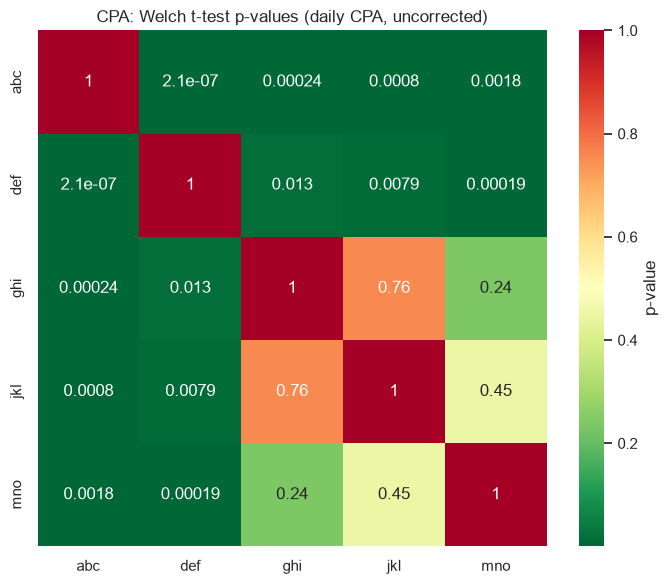

In [5]:
groups = sorted(paid.channel.unique())
pmat = pd.DataFrame(1.0, index=groups, columns=groups)      # 1. square, 1.0 on the diagonal
for r in cpa_res.itertuples():                              # 2. fill [a, b] and [b, a]
    pmat.loc[r.group_a, r.group_b] = r.p_value
    pmat.loc[r.group_b, r.group_a] = r.p_value

plt.figure(figsize=(7, 6))                                  # 3. heatmap with p-values written in
sns.heatmap(pmat, annot=True, fmt=".2g", cmap="RdYlGn_r", cbar_kws={"label": "p-value"})
plt.title("CPA: Welch t-test p-values (daily CPA, uncorrected)")
plt.tight_layout()
plt.savefig(OUT / "metric_comparison_heatmap.png", dpi=120)
plt.show()

**✍️ Which channels differ significantly? Which pairs can't be told apart?** 
- **CPA: 7 of 10 pairs differ.**
  - `abc` is cheaper than all four others. They cost 48% to 99% more per conversion (d = 0.71 to 1.15, medium to large). Caveat: `abc` has only 22 CPA days.
  - `ghi`, `jkl` and `mno` are each cheaper than `def`, by 18% to 25% of def's CPA (d = 0.37 to 0.57, small to medium).
- **Can't tell apart on CPA:** `ghi`, `jkl` and `mno` (gaps of 3% to 9%, p = 0.24 to 0.76, d below 0.2).
- **Daily conversion rate: 6 of 10 pairs differ.** `def` is lower than all four others, `abc` beats `mno`, and `ghi` beats `mno`. The pairs we can't tell apart: abc vs ghi, abc vs jkl, ghi vs jkl, jkl vs mno.


## Step 5: Fisher's exact test on conversions
Each click either converts or doesn't: **right/wrong data**, so Fisher's exact test .

```
[[conversions_A, non_conversions_A],
 [conversions_B, non_conversions_B]]
```

**What & why**
- Here the unit is the **click**, not the day: all clicks of the 91 days are pooled per channel. So **N = clicks**, from about 1.5 thousand (`abc`) to about 1.2 million (`ghi`).
- `diff_pp` = the gap in **percentage points** (e.g. 26.7% vs 23.5% = +3.2 points). `pct_diff` = the same gap in % of channel A.
- The odds ratio is a by-product of `fisher_exact`. Below 1 means channel A converts less than channel B.

In [6]:
conv = df.groupby("channel")[["conversions", "clicks"]].sum()
conv["non_conversions"] = conv.clicks - conv.conversions
conv["conv_rate"] = conv.conversions / conv.clicks
display(conv)

rows = []
for a, b in combinations(sorted(conv.index), 2):
    table = [[conv.loc[a, "conversions"], conv.loc[a, "non_conversions"]],
             [conv.loc[b, "conversions"], conv.loc[b, "non_conversions"]]]
    odds_ratio, p = fisher_exact(table, alternative="two-sided")
    rate_a, rate_b = conv.loc[a, "conv_rate"], conv.loc[b, "conv_rate"]
    rows.append({"group_a": a, "group_b": b,
                 "conv_a": conv.loc[a, "conversions"], "clicks_a": conv.loc[a, "clicks"],
                 "conv_b": conv.loc[b, "conversions"], "clicks_b": conv.loc[b, "clicks"],
                 "rate_a": rate_a, "rate_b": rate_b,
                 "diff_pp": (rate_b - rate_a) * 100,                  # percentage points
                 "pct_diff": (rate_b - rate_a) / rate_a * 100,        # % of A
                 "odds_ratio": odds_ratio, "p_value": p, "significant": p < ALPHA})
fisher_res = pd.DataFrame(rows)
print(f"Fisher: {len(fisher_res)} comparisons, {fisher_res.significant.sum()} significant\n")
for r in fisher_res.itertuples():
    flag = "SIGNIFICANT" if r.significant else "can't tell"
    print(f"{r.group_a} vs {r.group_b}: {r.rate_a:.1%} vs {r.rate_b:.1%} ({r.diff_pp:+.1f} pts) "
          f"| odds ratio = {r.odds_ratio:.2f} | p = {r.p_value:.2e} | {flag}")

,conversions,clicks,non_conversions,conv_rate
channel,,,,
abc,618,1477,859,0.418416
def,26716,173646,146930,0.153853
ghi,331992,1242602,910610,0.267175
jkl,19200,73754,54554,0.260325
mno,225991,960577,734586,0.235266


Fisher: 10 comparisons, 10 significant

abc vs def: 41.8% vs 15.4% (-26.5 pts) | odds ratio = 3.96 | p = 1.79e-129 | SIGNIFICANT
abc vs ghi: 41.8% vs 26.7% (-15.1 pts) | odds ratio = 1.97 | p = 4.41e-36 | SIGNIFICANT
abc vs jkl: 41.8% vs 26.0% (-15.8 pts) | odds ratio = 2.04 | p = 8.15e-39 | SIGNIFICANT
abc vs mno: 41.8% vs 23.5% (-18.3 pts) | odds ratio = 2.34 | p = 2.42e-54 | SIGNIFICANT
def vs ghi: 15.4% vs 26.7% (+11.3 pts) | odds ratio = 0.50 | p = 0.00e+00 | SIGNIFICANT
def vs jkl: 15.4% vs 26.0% (+10.6 pts) | odds ratio = 0.52 | p = 0.00e+00 | SIGNIFICANT
def vs mno: 15.4% vs 23.5% (+8.1 pts) | odds ratio = 0.59 | p = 0.00e+00 | SIGNIFICANT
ghi vs jkl: 26.7% vs 26.0% (-0.7 pts) | odds ratio = 1.04 | p = 4.28e-05 | SIGNIFICANT
ghi vs mno: 26.7% vs 23.5% (-3.2 pts) | odds ratio = 1.19 | p = 0.00e+00 | SIGNIFICANT
jkl vs mno: 26.0% vs 23.5% (-2.5 pts) | odds ratio = 1.14 | p = 1.22e-52 | SIGNIFICANT


**Conversion-rate chart, and Fisher vs t-test**
- The chart is sorted by rate, with % labels on the bars.
- The comparison puts both tests side by side for the same 10 pairs and lists the ones where they **disagree**.

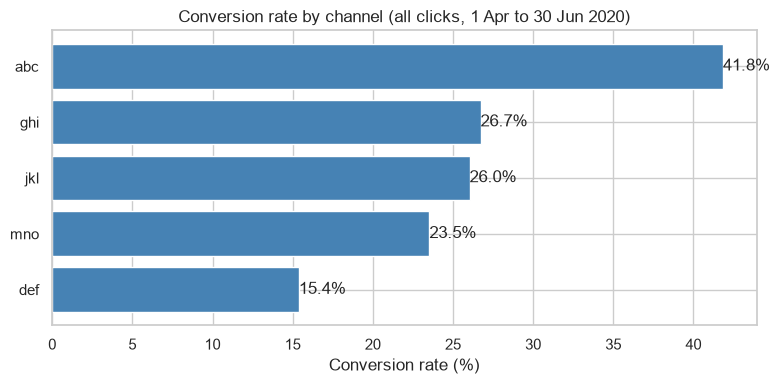

Significant in Fisher: 10 / 10 | in t-test: 6 / 10
Pairs significant in one test but not the other: 4


,group_a,group_b,diff_pp,p_value_fisher,p_value_ttest
1,abc,ghi,-15.12,4.411533e-36,0.351973
2,abc,jkl,-15.81,8.150140e-39,0.095564
7,ghi,jkl,-0.68,4.281056e-05,0.330195
9,jkl,mno,-2.51,1.220068e-52,0.068935


In [7]:
rates = conv["conv_rate"].sort_values()
plt.figure(figsize=(8, 4))
bars = plt.barh(rates.index, rates.values * 100, color="steelblue")
plt.bar_label(bars, fmt="%.1f%%")
plt.xlabel("Conversion rate (%)")
plt.title("Conversion rate by channel (all clicks, 1 Apr to 30 Jun 2020)")
plt.tight_layout()
plt.savefig(OUT / "rate_comparison.png", dpi=120)
plt.show()

# Fisher (N = clicks) vs t-test on daily conversion rates (N = days)
both = fisher_res.merge(cvr_t_res, on=["group_a", "group_b"], suffixes=("_fisher", "_ttest"))
disagree = both[both.significant_fisher != both.significant_ttest]
print(f"Significant in Fisher: {both.significant_fisher.sum()} / 10 | in t-test: {both.significant_ttest.sum()} / 10")
print(f"Pairs significant in one test but not the other: {len(disagree)}")
disagree[["group_a", "group_b", "diff_pp", "p_value_fisher", "p_value_ttest"]].round({"diff_pp": 2})

**✍️ Answer:**
1. **Significantly different conversion rates:** with Fisher, **all 10 pairs**. The order is `abc` 41.8% > `ghi` 26.7% > `jkl` 26.0% > `mno` 23.5% > `def` 15.4%.
2. **Large enough to matter?** Some are, some aren't:
   - **Yes:** `def` sits 8 to 11 points below ghi, jkl and mno (35% to 42% fewer conversions per click). `abc` is 15 to 26 points above everyone, but that rests on only 1,477 clicks.
   - **No (real but tiny):** ghi vs jkl (**0.7 points**), jkl vs mno (2.5) and ghi vs mno (3.2). None of these would change a budget decision on its own.
3. **Fisher vs t-test: they disagree on 4 pairs** (abc vs ghi, abc vs jkl, ghi vs jkl, jkl vs mno). Fisher says "significant", the t-test says "can't tell". 

**Why: N.**
   - Fisher's N is **clicks**, from 1,477 for abc to about 1.2 million for ghi. With an N that big, even a 0.7-point gap clears the bar (§3b: more data shrinks the zone of indistinguishability).
   - The t-test's N is **days** (91; abc 24), and it sees how much the daily conversion rate swings, so small gaps stay inside the noise.
   - Fisher also treats every click as independent. Clicks on the same day share conditions (campaign mix, traffic), so Fisher overstates how sure we are. For a budget decision, the daily t-test is the more honest read.

### Save the results for notebooks 03 to 05

In [8]:
cpa_res.to_csv(OUT / "results_cpa_ttest.csv", index=False)
cvr_t_res.to_csv(OUT / "results_conv_rate_ttest.csv", index=False)
fisher_res.to_csv(OUT / "results_conv_rate_fisher.csv", index=False)
print("Saved 3 result tables to", OUT)

Saved 3 result tables to outputs
